Compare active and idle states of IOT devices

Code structure: if possible have data and display independent, so that time can be saved by not recomputing unchanged data

e.g

```python
show_data(get_data())
```

rather than

```python
def show_data():
    get_data()
```

also increases configurability

Terms:

- Class
- Window (w seconds long)
- Shift (s seconds)


In [46]:
%load_ext autoreload
%autoreload 2
# function defs

from functools import partial
from util import *

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-paper')
import matplotlib.ticker as ticker
import yaml
import seaborn as sns
from pandas.io.formats.style import Styler
import subprocess


from playwright.async_api import async_playwright





async def typst_table(
    s: Styler, name: str, headless=True
):  
    display(s)

    # Starting playwright here is more overhead but means you can see headless
    playwright = await async_playwright().start()
    browser = await playwright.chromium.launch(headless = headless)
    page = await browser.new_page()
    
    table_path = Path(f"../assets/table_{name}")
    html_path = (table_path.parent / (table_path.name + '.html')).resolve()
    pdf_path = (table_path.parent / (table_path.name + '.pdf')).resolve()

    # add the html stuff, including mathjax and css
    with open("render.html", "r") as f:
        head = f.read()

        with open(html_path, "w") as combo:
            combo.write(head + "<body title='body'>" + s.to_html() + "</body>")

    # playwright requires an absolute url
    await page.goto(html_path.as_uri())
    # find out the widths and heights
    await page.emulate_media(media="screen")
    box = await page.get_by_title("body").bounding_box()
    print(box)
    box = await page.get_by_role("table").bounding_box()
    print(box)
    await page.pdf(path=pdf_path, width = box["width"], height=box["height"])

c = Context("../../PowerIDS/classifier/power_csv")
with open("../common.yaml") as f:
    config = yaml.safe_load(f)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
# | label: safenetiot

exp = Experiment(
    c,
    [State.IDLE, State.ACTIVE],
    [Metric.MEAN],
    Classifier.Centroid,
    config["w"],
    config["s"],
)
nice_cats = ["Lights", "Audio", "Camera", "TV", "Appliance"]
categories = {cat: [] for cat in c.categories}
for dev in exp.devices:
    categories[dev.category].append(dev)
# print(categories)
categories = {nice_cats[i]: pd.Series(l) for i, l in enumerate(categories.values())}

await typst_table(
    pd.DataFrame(data=categories).fillna("").style.hide(axis="index"), "categories"
)

Lights,Audio,Camera,TV,Appliance
Antela Light,Bose Speaker,Amcrest Camera,Apple TV,Cosori Air Fryer
Fitop Light,Echo Dot 5 Speaker,Blurams Camera,LG TV,Honeywell Thermostat
LIFX Light,Echo Spot 5 Speaker,Boifun Baby Camera,"Samsung 32"" TV",Levoit Air Purifier
Lepro Light,Google Home Speaker,Google Nest Camera,Samsung Small TV,Swan Smart Kettle
Tapo Light,Homepod Speaker,Hualai Camera,TCL TV,Weekett Kettle
Wiz Light,Nest Mini 2 Speaker,Yi Camera,Toshiba TV,Xiaomi Blender
Yeelight Light,Sonos Speaker,,,


{'x': 8, 'y': 8, 'width': 667.6875, 'height': 178}


In [54]:
# | label: summary

common = partial(
    Experiment, c, classify_by=Classifier.Median, w=config["w"], s=config["s"]
)

summary_idle_mean = common([State.IDLE], [Metric.MEAN])

summary_active_mean = common([State.ACTIVE], [Metric.MEAN])

summary_idle_mean_std = common([State.IDLE], [Metric.MEAN, Metric.STD])

summary_active_mean_std = common([State.ACTIVE], [Metric.MEAN, Metric.STD])
mean_fancy = Metric.MEAN.fancy_name()
std_fancy = Metric.STD.fancy_name()

scores = pd.DataFrame(
    data={
        "$\\boldsymbol{M^I_{\\mu}}$": summary_idle_mean.f1_scores.values(),
        "$\\boldsymbol{M^I_{\\mu \\sigma}}$": summary_idle_mean_std.f1_scores.values(),
        "$M^A_{\\mu}$": summary_active_mean.f1_scores.values(),
        "$M^A_{\\mu \\sigma}$": summary_active_mean_std.f1_scores.values(),
    },
    index=exp.devices,
)
scores["removeme"] = scores.sum(axis=1)
scores = scores.sort_values(by="removeme", ascending=False)
scores = scores.drop("removeme", axis=1)
scores.loc["Macro Average"] = [
    summary_idle_mean.f1_macro_average,
    summary_idle_mean_std.f1_macro_average,
    summary_active_mean.f1_macro_average,
    summary_active_mean_std.f1_macro_average,
]

scores.columns.name = "IoT Device"
# typst_table(scores.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1), "summary")
scores.columns.name = "ah"
await typst_table(scores.iloc[-1:, :].style.format(precision=3), "mini")




ah,$\boldsymbol{M^I_{\mu}}$,$\boldsymbol{M^I_{\mu \sigma}}$,$M^A_{\mu}$,$M^A_{\mu \sigma}$
Macro Average,0.717,0.793,0.857,0.915


{'x': 0, 'y': 0, 'width': 1280, 'height': 720}
{'x': 495.90625, 'y': 0, 'width': 288.171875, 'height': 56.3125}


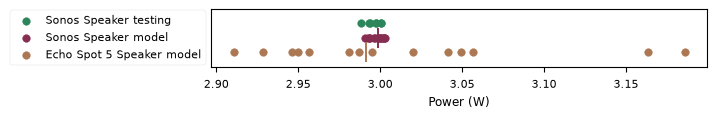

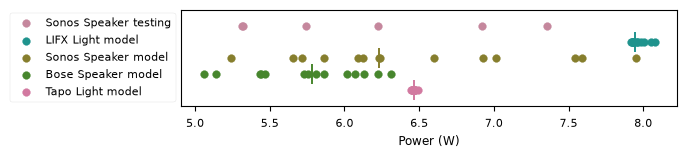

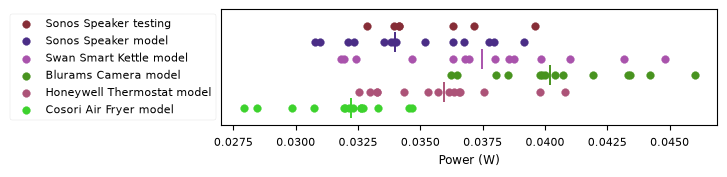

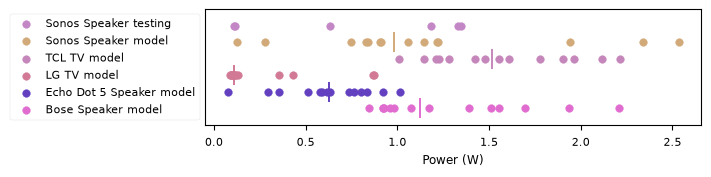

In [4]:
# | label: confused with

# for a device, see what other devices it is confused with
# [ for device, class_ in all.classes.items() if class]


# lifx = all.devices[2]
# 1 function for getting data either training or otherwise to plot.


# 1 function to actually plot it
def confused_with(exp: Experiment, name: str, state: State) -> list[Trace]:
    # return training traces that are confused with the device, and the devices training and testing traces.
    device = exp.get_device(name)
    combo = (device, state)
    selected_data = exp.get_data(*combo)[0]
    confused = list(exp.classes[combo].keys())
    traces = [exp.get_data(*c)[0].training for c in confused]
    if combo not in confused:
        traces = [selected_data.training] + traces

    # TODO: ensure device is first
    traces = [selected_data.testing] + traces
    return traces


def plot_metrics(exp: Experiment, to_plot: list[Trace], log_scale=False):
    if len(exp.metrics) > 1:
        raise ValueError

    fig, ax = plt.subplots()

    n = len(to_plot)
    for i, trace in enumerate(to_plot):
        metric = [profile[exp.metrics[0]] for profile in trace.profile]
        colour = ColorHash((trace)).hex
        ax.scatter(
            metric,
            [n - i] * len(trace.profile),
            label=f"{trace.data.device.name()} {trace.type}",
            c=colour,
        )
        if trace.type == TraceType.TRAINING:
            ax.scatter(np.median(metric), n - i, marker="|", c=colour, s=200)
    if log_scale:
        ax.set_xscale("log")

    ax.set_ylim((0, n + 1))
    ax.legend(loc="center right", bbox_to_anchor=(0, 0.5))
    ax.set_yticks([])
    fig.set_figheight(n / 4)

    ax.set_xlabel("Power (W)")


plot_metrics(summary_idle_mean, confused_with(summary_idle_mean, "sonos", State.IDLE))

plot_metrics(
    summary_active_mean, confused_with(summary_active_mean, "sonos", State.ACTIVE)
)

# TODO mode to plot overlapping distributions
# TODO randomly selected windows, are there startup effects?

std_idle = common([State.IDLE], [Metric.STD])
std_active = common([State.ACTIVE], [Metric.STD])
plot_metrics(std_idle, confused_with(std_idle, "sonos", State.IDLE))

plot_metrics(std_active, confused_with(std_active, "sonos", State.ACTIVE))
plt.show()

In [5]:
# | label: results

common = partial(
    Experiment, c, classify_by=Classifier.Median, w=config["w"], s=config["s"]
)



scores.columns.name = "IoT Device"
typst_table(scores.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1), "summary")

IoT Device,$M$,"Idle by ,",Active by,"Active by ,"
Amcrest Camera,1.000000,1.000000,1.000000,1.000000
Yi Camera,1.000000,1.000000,1.000000,1.000000
Samsung Small TV,1.000000,1.000000,0.857143,1.000000
Nest Mini 2 Speaker,1.000000,1.000000,0.857143,1.000000
Cosori Air Fryer,1.000000,1.000000,1.000000,0.857143
"Samsung 32"" TV",1.000000,1.000000,0.857143,1.000000
Levoit Air Purifier,1.000000,1.000000,0.923077,0.923077
Boifun Baby Camera,0.933333,0.875000,1.000000,1.000000
Tapo Light,0.933333,1.000000,0.857143,1.000000
LG TV,1.000000,1.000000,0.857143,0.923077


IoT Device,$M$,"Idle by ,",Active by,"Active by ,"
Amcrest Camera,1.000000,1.000000,1.000000,1.000000
Yi Camera,1.000000,1.000000,1.000000,1.000000
Samsung Small TV,1.000000,1.000000,0.857143,1.000000
Nest Mini 2 Speaker,1.000000,1.000000,0.857143,1.000000
Cosori Air Fryer,1.000000,1.000000,1.000000,0.857143
"Samsung 32"" TV",1.000000,1.000000,0.857143,1.000000
Levoit Air Purifier,1.000000,1.000000,0.923077,0.923077
Boifun Baby Camera,0.933333,0.875000,1.000000,1.000000
Tapo Light,0.933333,1.000000,0.857143,1.000000
LG TV,1.000000,1.000000,0.857143,0.923077


TypeError: unsupported operand type(s) for -: 'Data' and 'Data'

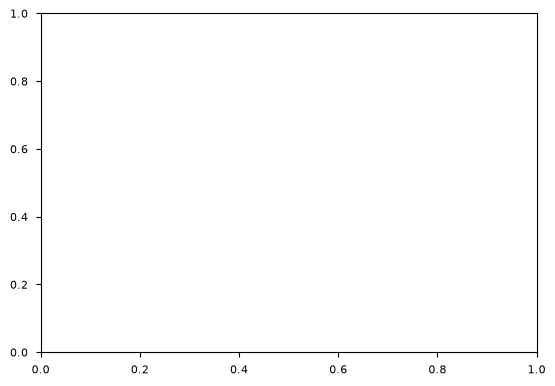

In [6]:
# | label: mu sigma

mu_sigma = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    config["w"],
    config["s"],
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)

mu_sigma = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    config["w"],
    config["s"],
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)

In [ ]:
# | label: confusion matrix
idle = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN],
    Classifier.Median,
    config["w"],
    config["s"],
)
graph_confusion_matrix(idle)

active = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN],
    Classifier.Median,
    config["w"],
    config["s"],
)
graph_confusion_matrix(active)
mean = pd.DataFrame(
    data={
        "Macro Average F1 score": [idle.f1_macro_average, active.f1_macro_average],
        "Devices with Precision > 90%": [
            f"{len([score for score in idle.precision.values() if score >= 0.9])} / {len(idle.devices)}",
            f"{len([score for score in active.precision.values() if score >= 0.9])} / {len(active.devices)}",
        ],
    },
    index=["Idle", "Average"],
)
mean.columns.name = "State"
typst_table(
    mean.style.format(precision=3),
    "mean",
)
plt.show()

In [ ]:
# | label: fft

fft = Experiment(
    c,
    [State.IDLE],
    [Metric.FFT],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(fft)

fft_both = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN, Metric.FFT],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(fft_both)

In [ ]:
# | label: combined

both = Experiment(
    c,
    states=[State.IDLE, State.ACTIVE],
    metrics=[Metric.MEAN],
    classify_by=Classifier.Median,
    w=config["w"],
    s=config["s"],
)

# both.f1_macro_average

both_mu_sigma = Experiment(
    c,
    states=[State.IDLE, State.ACTIVE],
    metrics=[Metric.MEAN, Metric.STD],
    classify_by=Classifier.Median,
    w=config["w"],
    s=config["s"],
)

# both_mu_sigma.f1_macro_average

# accuracy at picking state, assumes only 2 states

state = {state: [0.0, 0.0] for state in State}
state['overall'] = [0, 0]
state['overall'][0] = both_mu_sigma.f1_macro_average

state['overall'][1] = both_mu_sigma.f1_macro_average
for (_, real_state), counter in both.classes.items():
    total = 0
    for (_, predicted_state), count in counter.items():
        if predicted_state == real_state:
            total += count

    state[real_state][0] += total / counter.total() / len(both.devices)

for (_, real_state), counter in both_mu_sigma.classes.items():
    total = 0
    for (_, predicted_state), count in counter.items():
        if predicted_state == real_state:
            total += count

    state[real_state][1] += total / counter.total() / len(both.devices)
    # distributive
both = pd.DataFrame(
    data=state, index=[f"{mean_fancy}", f"{mean_fancy} and {std_fancy}"]
)
# both.columns
both.columns = both.columns.str.capitalize()
typst_table(
    both.style.format(precision=3),
    "both",
)

# graph_confusion_matrix(both)

In [ ]:
# | label: my dataset
import csv
import os

# figure out how much data there is
BASE_PATH = "../data"
mydata = Context(BASE_PATH, categories=False)
# Experiment(mydata, states=[State.IDLE])
files = {device: os.listdir(f"{BASE_PATH}/{device}") for device in mydata.devices}


def get_file_length(filename):
    df = pd.read_csv(filename)
    # print(filename, len(df.index))
    return len(df.index)


# get_file_length("./data/GoogleNestHub/2026-10-26T16:20:56.474563.csv")
lengths = {
    device: [get_file_length(f"{BASE_PATH}/{device}/{file}") for file in files]
    for device, files in files.items()
}

data_stats = pd.DataFrame(
    data={
        "Files": [len(files[device]) for device in mydata.devices],
        "Total Length (hours)": [
            sum(lengths[device]) / 60 / 60 for device in mydata.devices
        ],
    },
    index=mydata.devices,
)

# printdata_stats.agg(sum).to_frame("Total")
bold = lambda x: "font-weight: bold"

typst_table(
    data_stats.style.format(precision=0).concat(
        data_stats.agg(sum)
        .to_frame("Total")
        .transpose()
        .style.format(precision=0)
        .map_index(bold)
        .map(bold)
    ),
    "mydata",
)

In [ ]:
%autoreload 2

c = Context("../PowerIDS/classifier/power_csv")
for threshold in [None, 0, 1, 2, 3, 4]:
    exp = Experiment(
        c,
        [State.IDLE],
        [Metric.MEAN],
        Classifier.Median,
        config['w'],
        config['s'],
        threshold=threshold,
        # include=["appletv", "samsungtv", "cosori"],
    )
    graph_confusion_matrix(exp)
    print(threshold, exp.f1_macro_average, np.mean(list(exp.unknown.values())))
# print(exp.classes)
# print(len(exp.devices), len(exp.data))
# # nice_names = [print(data) for data in exp.data]
# print(exp.data)
# # display(
# #     pd.DataFrame(
# #         data=exp.confusion_matrix, columns=nice_names
# #     ).style  # .format(precision=2)
# # )
# print(exp.f1_scores)

# TODO version of f1 including and excluding unknowns